# Imports:

In [3]:
import pandas as pd
import requests
import numpy as np
from PIL import Image
from datasets import load_dataset, Image as HFImage
import base64
from io import BytesIO
from PIL import Image
from IPython.display import HTML
import torch
from torchvision import models

# Example Instance

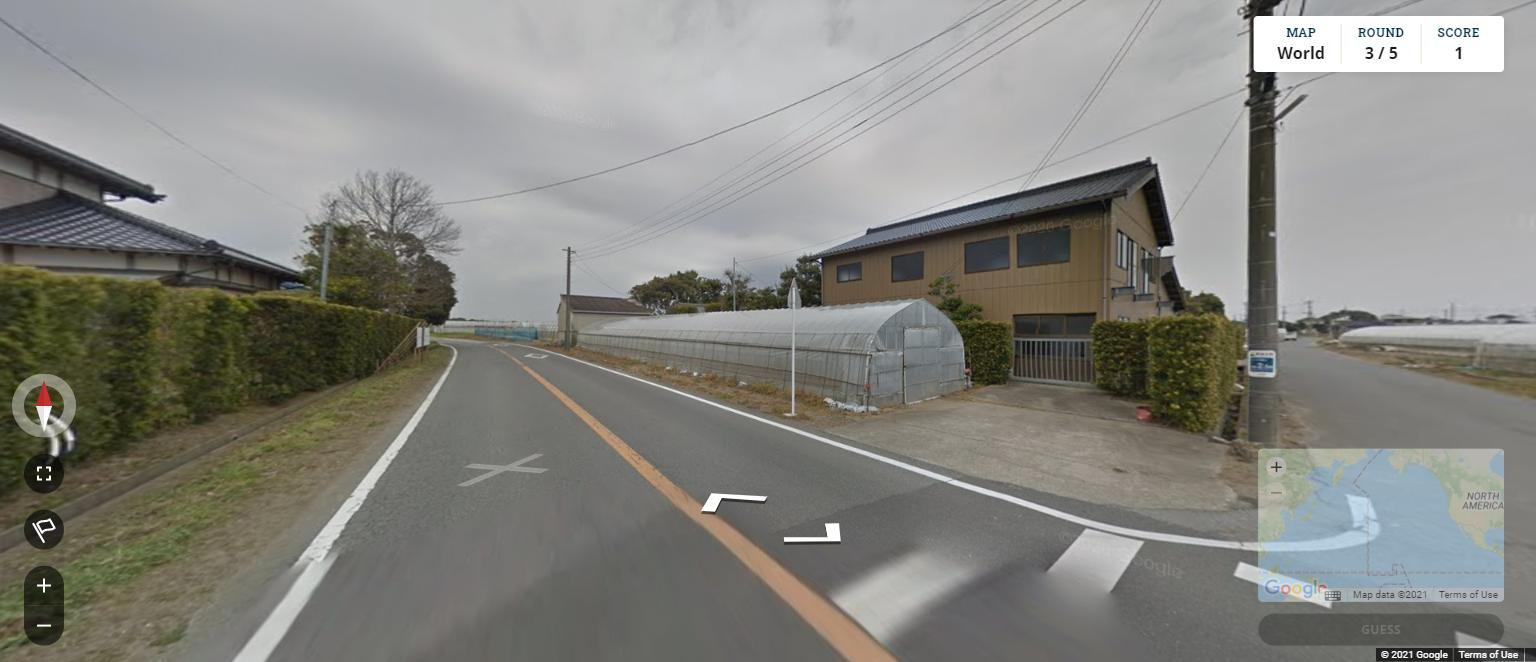

Country: Japan


In [4]:
ds = load_dataset("moondream/geoguessr-countries-finetune", split="train")
ds = ds.cast_column("image", HFImage(decode=True))

sample = ds[0]
display(sample["image"])  
print("Country:", sample["country"])

,image,country
0,,Japan
1,,South Africa
2,,Australia
3,,Chile
4,,Australia

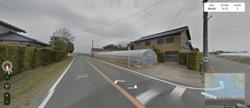
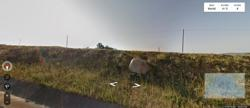
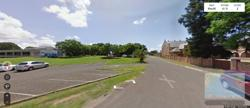
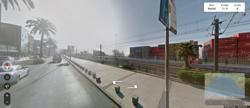
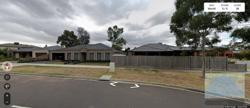

In [5]:
def head(ds, n=5, width=250):
    df = ds.select(range(n)).to_pandas()

    def to_img_tag(img):
        im = Image.open(BytesIO(img["bytes"]))
        im.thumbnail((width, width))
        buf = BytesIO()
        im.save(buf, format="JPEG")
        b64 = base64.b64encode(buf.getvalue()).decode()
        return f'<img src="data:image/jpeg;base64,{b64}" width="{width}">'

    df["image"] = df["image"].apply(to_img_tag)
    return HTML(df.to_html(escape=False))

head(ds)

In [6]:
ds.to_pandas()["country"].value_counts()

country
Japan             2673
France            2487
United Kingdom    1723
Brazil            1613
Russia            1225
Australia         1187
Canada             963
South Africa       821
Spain              748
Finland            728
Thailand           653
Mexico             627
Poland             600
Italy              550
Sweden             506
Singapore          491
Germany            485
Argentina          478
Norway             471
Netherlands        404
New Zealand        387
Taiwan             382
Malaysia           294
Austria            241
Romania            239
Israel             225
Chile              224
Ireland            203
Indonesia          199
Peru               188
Turkey             185
Czechia            178
Colombia           173
Greece             173
South Korea        169
Portugal           168
Philippines        151
Bulgaria           151
Belgium            150
Denmark            134
Switzerland        120
Hungary            116
India              112
Bot

# Methods
1. Run the images through a pretrained CNN or CLIP once to get embeddings
2. Train your logistic regression, SVM, and gradient boosting models on those embeddings.
3. Fine-tune the CNN itself as a fourth, “deep learning” model to compare against.

In [10]:
from io import BytesIO
from PIL import Image

def get_img(sample):
    img = sample["image"]
    if isinstance(img, dict):          # decode=False → raw bytes
        img = Image.open(BytesIO(img["bytes"]))
    return img.convert("RGB")

In [ ]:
weights = models.ResNet50_Weights.DEFAULT
cnn = models.resnet50(weights=weights) # embedding models
cnn.fc = torch.nn.Identity()          # drop classifier → outputs 2048-dim features
cnn.eval()
preprocess = weights.transforms()

@torch.no_grad()
def cnn_embed(samples):
    batch = torch.stack([preprocess(get_img(s)) for s in samples])
    return cnn(batch).numpy()

X = cnn_embed([ds[i] for i in range(8)])
print(X.shape)   # (8, 2048)

(8, 2048)


Next Meeting 
1. Determine Embedding model
2. Assign models
   1. 2 models each
3. Fine tune final model/ test model (ensemble?)